In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

try:
    import fitsio
    HAS_FITSIO = True
except Exception:
    from astropy.table import Table
    HAS_FITSIO = False

from astropy.coordinates import SkyCoord
import astropy.units as u

In [2]:
ROOT = Path.home() / "project"
INTER = ROOT / "data" / "interm" / "new_d_y3_clean.fits"
PROC  = ROOT / "data" / "processed"
SPLIT = PROC / "splits"

ZBINS = {
    1: (2.3, 2.4),
    2: (2.4, 2.5),
    3: (2.5, 2.6),
    4: (2.6, 2.8),
}

def read_fits_selected(path, cols):
    if HAS_FITSIO:
        with fitsio.FITS(str(path)) as f:
            data = f[1].read(columns=cols)
        return data
    else:
        t = Table.read(str(path), hdu=1)
        return t[cols]

def load_intermediate_subset_for_bin(idx):
    zmin, zmax = ZBINS[idx]
    cols = ["Z", "TARGET_RA", "TARGET_DEC", "APP_MAG_R", "APP_MAGERR_R", "K_R", "K_R_ERR", "MU"]
    d = read_fits_selected(INTER, cols)

    z = np.asarray(d["Z"], dtype=float)
    sel = (z >= zmin) & (z < zmax)

    out = {
        "z": z[sel],
        "ra": np.asarray(d["TARGET_RA"], dtype=float)[sel],
        "dec": np.asarray(d["TARGET_DEC"], dtype=float)[sel],
        "m": np.asarray(d["APP_MAG_R"], dtype=float)[sel],
        "sigma_m": np.asarray(d["APP_MAGERR_R"], dtype=float)[sel],
        "k": np.asarray(d["K_R"], dtype=float)[sel],
        "sigma_k": np.asarray(d["K_R_ERR"], dtype=float)[sel],
        "mu": np.asarray(d["MU"], dtype=float)[sel],
    }
    return out

def load_split_masks(idx):
    zmin, zmax = ZBINS[idx]
    tag = f"bin{idx}_z{zmin}-{zmax}"
    s = np.load(SPLIT / f"{tag}_split.npz")
    return {
        "all": s["all"].astype(bool),
        "upper": s["upper"].astype(bool),
        "lower": s["lower"].astype(bool),
        "tag": tag,
    }

In [28]:
idx = 4   # change bin here
bin_data = load_intermediate_subset_for_bin(idx)
masks = load_split_masks(idx)

print("N from intermediate subset:", len(bin_data["z"]))
print("N from split all mask      :", masks["all"].sum())
print("N upper/lower              :", masks["upper"].sum(), masks["lower"].sum())

N from intermediate subset: 38558
N from split all mask      : 38558
N upper/lower              : 32102 6456


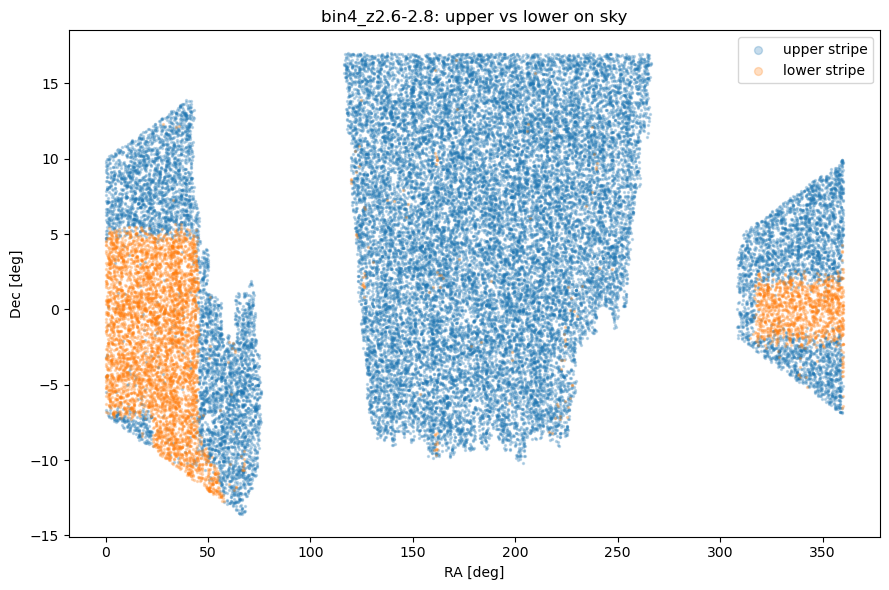

In [29]:
ra = bin_data["ra"]
dec = bin_data["dec"]
upper = masks["upper"]
lower = masks["lower"]

plt.figure(figsize=(9, 6))
plt.scatter(ra[upper], dec[upper], s=2, alpha=0.25, label="upper stripe")
plt.scatter(ra[lower], dec[lower], s=2, alpha=0.25, label="lower stripe")
plt.xlabel("RA [deg]")
plt.ylabel("Dec [deg]")
plt.title(f"{masks['tag']}: upper vs lower on sky")
plt.legend(markerscale=4)
plt.tight_layout()
plt.show()

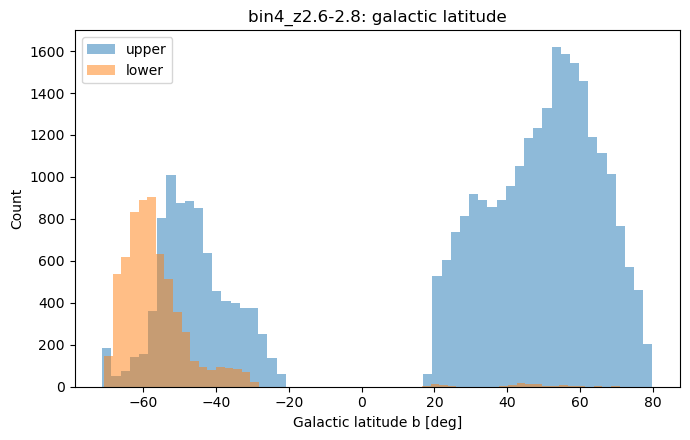

In [30]:
coords = SkyCoord(ra=ra*u.deg, dec=dec*u.deg, frame="icrs")
b = coords.galactic.b.deg

plt.figure(figsize=(7,4.5))
plt.hist(b[upper], bins=60, alpha=0.5, label="upper")
plt.hist(b[lower], bins=60, alpha=0.5, label="lower")
plt.xlabel("Galactic latitude b [deg]")
plt.ylabel("Count")
plt.title(f"{masks['tag']}: galactic latitude")
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
des_like = (b < 0) & (dec < 5)

n_upper_des = np.sum(upper & des_like)
n_lower_des = np.sum(lower & des_like)

frac_upper_des = n_upper_des / np.sum(upper)
frac_lower_des = n_lower_des / np.sum(lower)

print(f"Upper in DES-like region: {n_upper_des} / {np.sum(upper)} = {frac_upper_des:.3f}")
print(f"Lower in DES-like region: {n_lower_des} / {np.sum(lower)} = {frac_lower_des:.3f}")

Upper in DES-like region: 5382 / 32102 = 0.168
Lower in DES-like region: 6285 / 6456 = 0.974


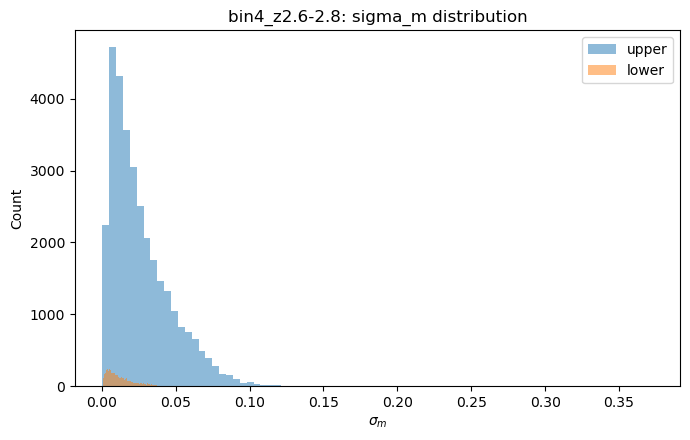

In [32]:
sigma_m = bin_data["sigma_m"]

plt.figure(figsize=(7,4.5))
plt.hist(sigma_m[upper], bins=80, alpha=0.5, label="upper")
plt.hist(sigma_m[lower], bins=80, alpha=0.5, label="lower")
plt.xlabel(r"$\sigma_m$")
plt.ylabel("Count")
plt.title(f"{masks['tag']}: sigma_m distribution")
plt.legend()
plt.tight_layout()
plt.show()